# SPiCe Tutorial: Modelling Epithelial-Mesenchymal Plasticity

This notebook demonstrates the full SPiCe workflow for breast cancer Xenium
spatial transcriptomics data using the `spice.tl` / `spice.pl` API.

All tool functions modify `adata` in place — results are stored in
`adata.obs`, `adata.obsm` and `adata.uns['spice']`.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import numpy as np
import pandas as pd
import scanpy as sc
import enrichmap as em
import spice

In [4]:
sc.set_figure_params(frameon=False)

In [5]:
project_dir = "/home/cenk/Withnell_spice/"
os.chdir(project_dir)

figures_dir = project_dir +"figures/"

## 1. Load data into AnnData

In [6]:
adata = sc.read_h5ad("processed_data/xenium_v1_hallmark_spice_results.h5ad")

In [7]:
spice.tl.build_graph(adata, n_neighbors=12, celltype_key="celltype_minor")

In [8]:
spice.tl.cross_validate(adata, feature_mode="celltype")


Fold 1/5


  Epoch    0 | Loss 0.3454 | Test AUC: 0.6283


  Epoch  100 | Loss 0.2540 | Test AUC: 0.7975


  Epoch  200 | Loss 0.2496 | Test AUC: 0.8048


  Epoch  300 | Loss 0.2470 | Test AUC: 0.8056


  Epoch  400 | Loss 0.2455 | Test AUC: 0.8063


... (21 outputs left out)

  Epoch  200 | Loss 0.2451 | Test AUC: 0.7736


  Epoch  300 | Loss 0.2439 | Test AUC: 0.7731


  Epoch  400 | Loss 0.2420 | Test AUC: 0.7732


  Epoch  499 | Loss 0.2411 | Test AUC: 0.7730

Mean performance: 0.7950 ± 0.0278


In [9]:
spice.tl.explain_nodes(adata, n_explanations=300)

Computing node explanations for label 0...


Label 0:   0%|          | 0/300 [00:00<?, ?it/s]

Label 0:   0%|          | 1/300 [00:25<2:08:18, 25.75s/it]

Label 0:   1%|          | 2/300 [00:55<2:19:38, 28.11s/it]

Label 0:   1%|▏         | 4/300 [01:24<1:36:34, 19.57s/it]

Label 0:   2%|▏         | 5/300 [01:50<1:46:03, 21.57s/it]

... (970 outputs left out)

Permutation:  99%|█████████▉| 298/300 [1:42:53<00:41, 20.79s/it]

Permutation: 100%|█████████▉| 299/300 [1:43:14<00:20, 20.87s/it]

Permutation: 100%|██████████| 300/300 [1:43:35<00:00, 20.83s/it]

Permutation: 100%|██████████| 300/300 [1:43:35<00:00, 20.72s/it]

(<Figure size 1040x640 with 4 Axes>,
 array([<Axes: title={'center': 'EPI'}, ylabel='$-\\log_{10}(p)$'>,
        <Axes: title={'center': 'H-EPI'}, ylabel='$-\\log_{10}(p)$'>,
        <Axes: title={'center': 'H-MES'}, ylabel='$-\\log_{10}(p)$'>,
        <Axes: title={'center': 'MES'}, ylabel='$-\\log_{10}(p)$'>],
       dtype=object))

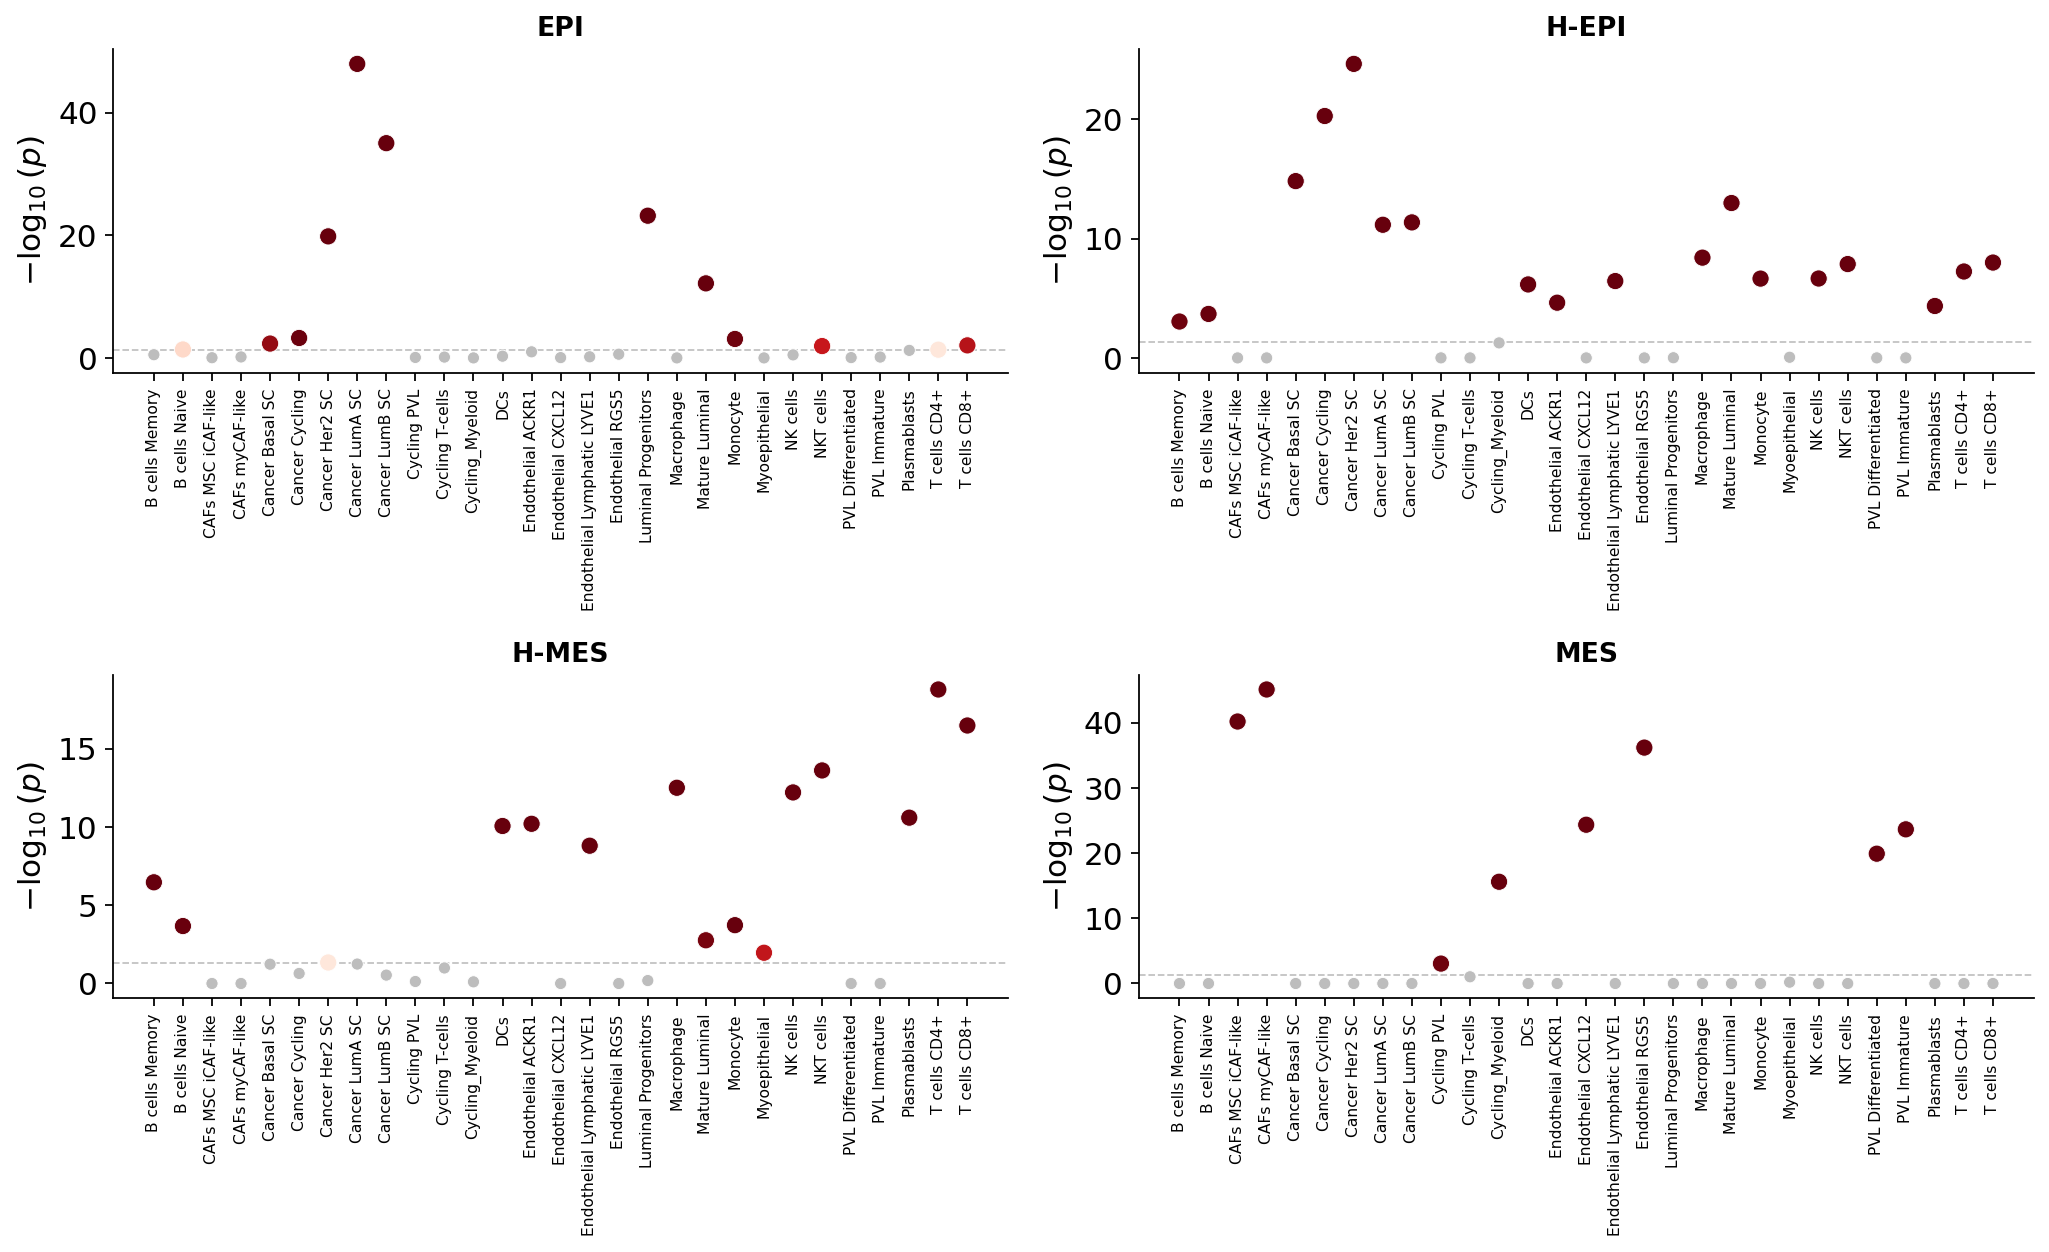

In [10]:
spice.pl.node_importance(
    adata,
    state_map={0: "EPI", 1: "H-EPI", 2: "H-MES", 3: "MES"},
    save="xenium_v1_hallmark_node_importance.pdf"
)

Edge explanations for label 0...


Label 0:   0%|          | 0/600 [00:00<?, ?it/s]

Label 0:   0%|          | 1/600 [02:07<21:16:42, 127.88s/it]

Label 0:   0%|          | 2/600 [04:15<21:11:18, 127.56s/it]

Label 0:   0%|          | 3/600 [06:21<21:05:40, 127.20s/it]

Label 0:   1%|          | 4/600 [08:26<20:51:58, 126.04s/it]

... (2,402 outputs left out)

Label 3: 100%|█████████▉| 598/600 [11:42:47<04:10, 125.02s/it]

Label 3: 100%|█████████▉| 599/600 [11:44:53<02:05, 125.11s/it]

Label 3: 100%|██████████| 600/600 [11:46:58<00:00, 125.11s/it]

Label 3: 100%|██████████| 600/600 [11:46:58<00:00, 70.70s/it] 

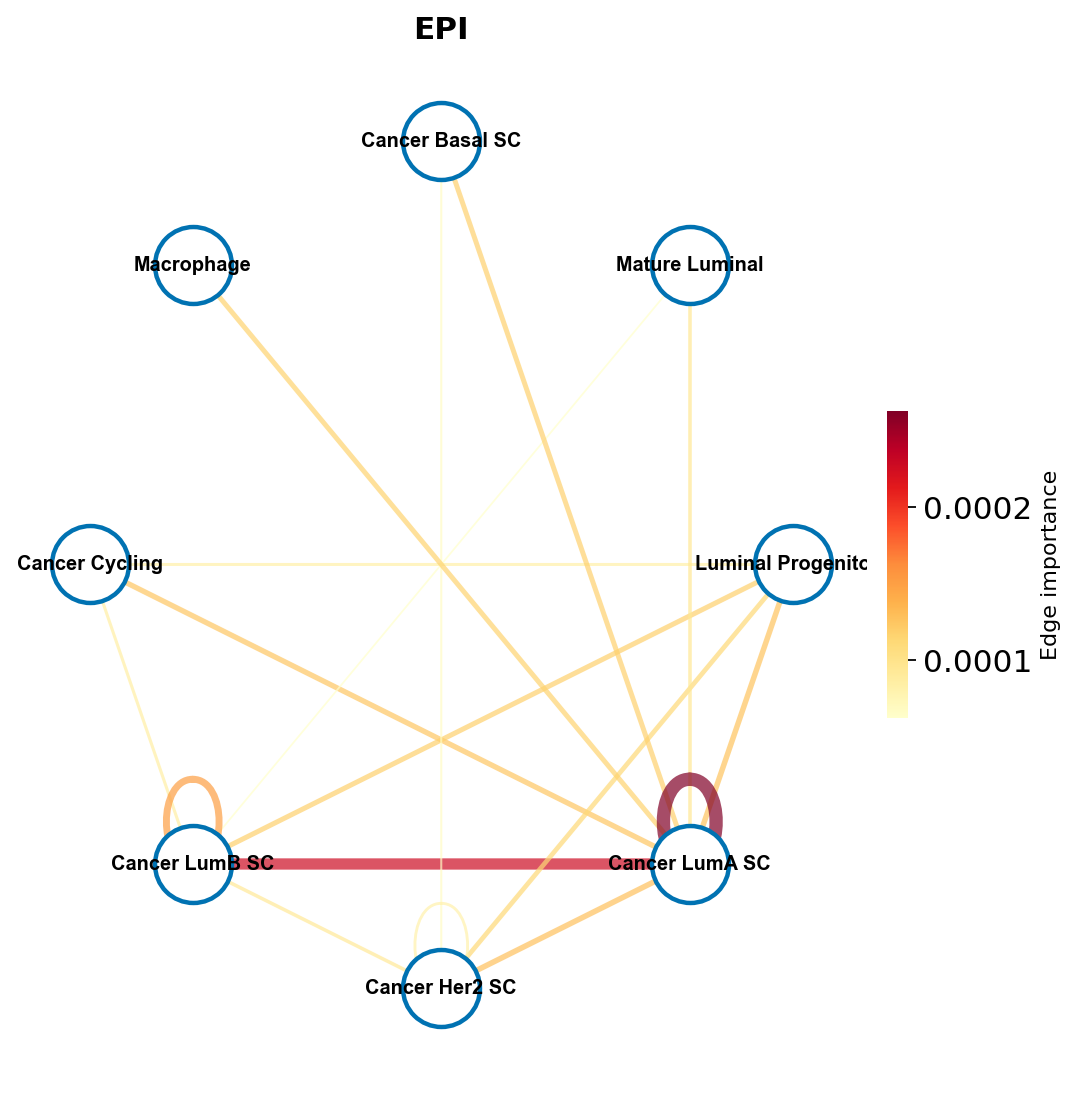

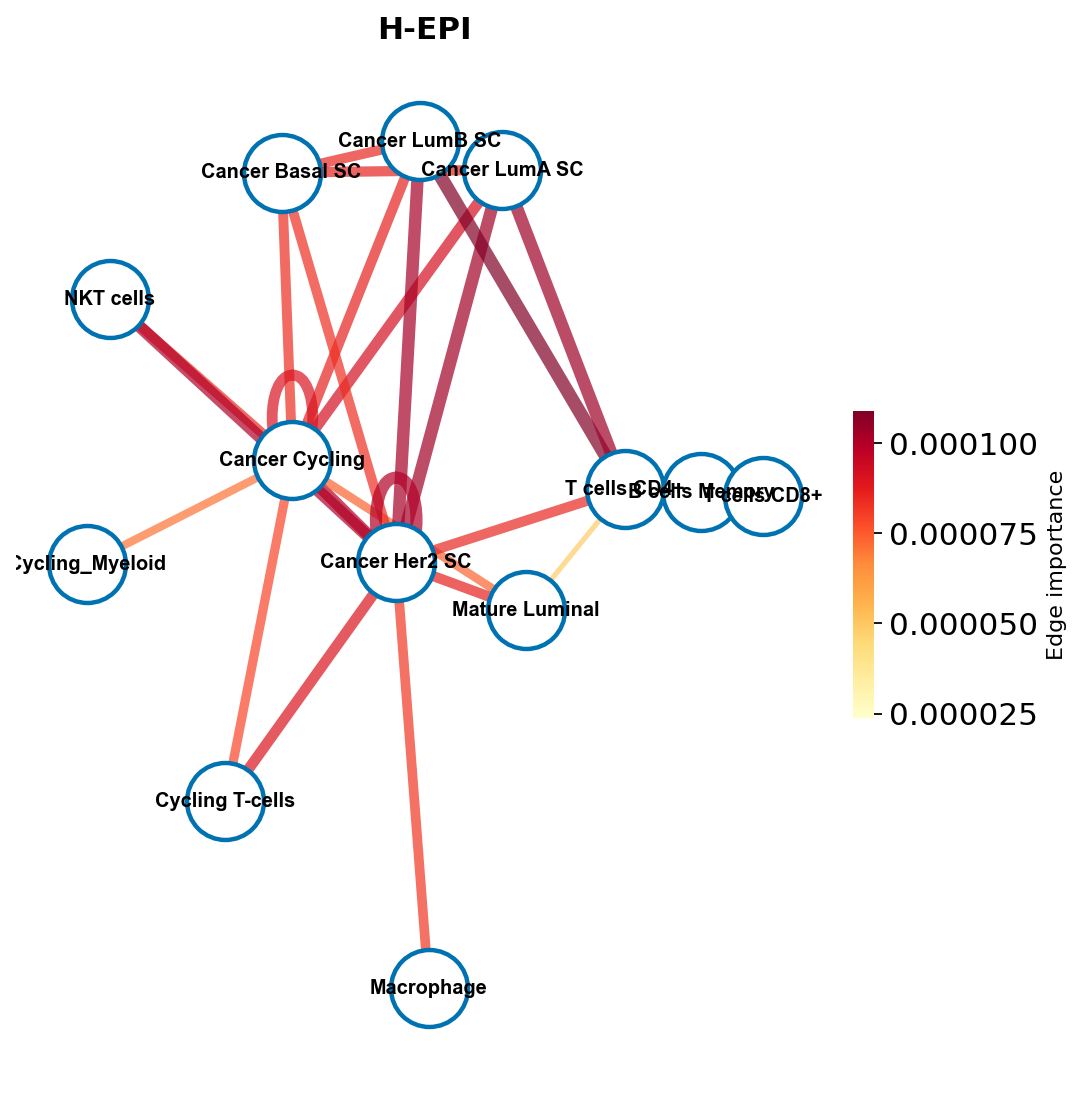

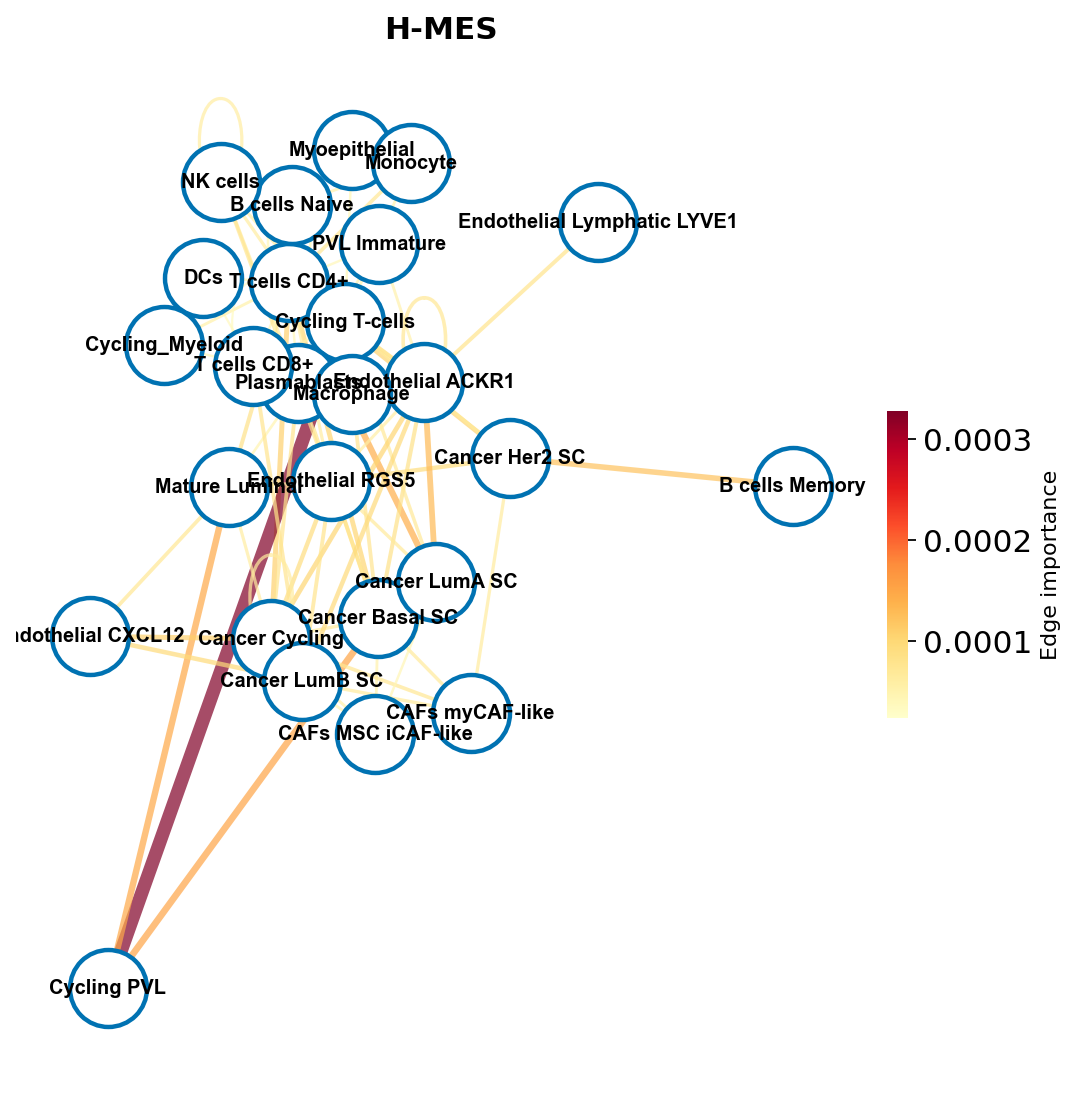

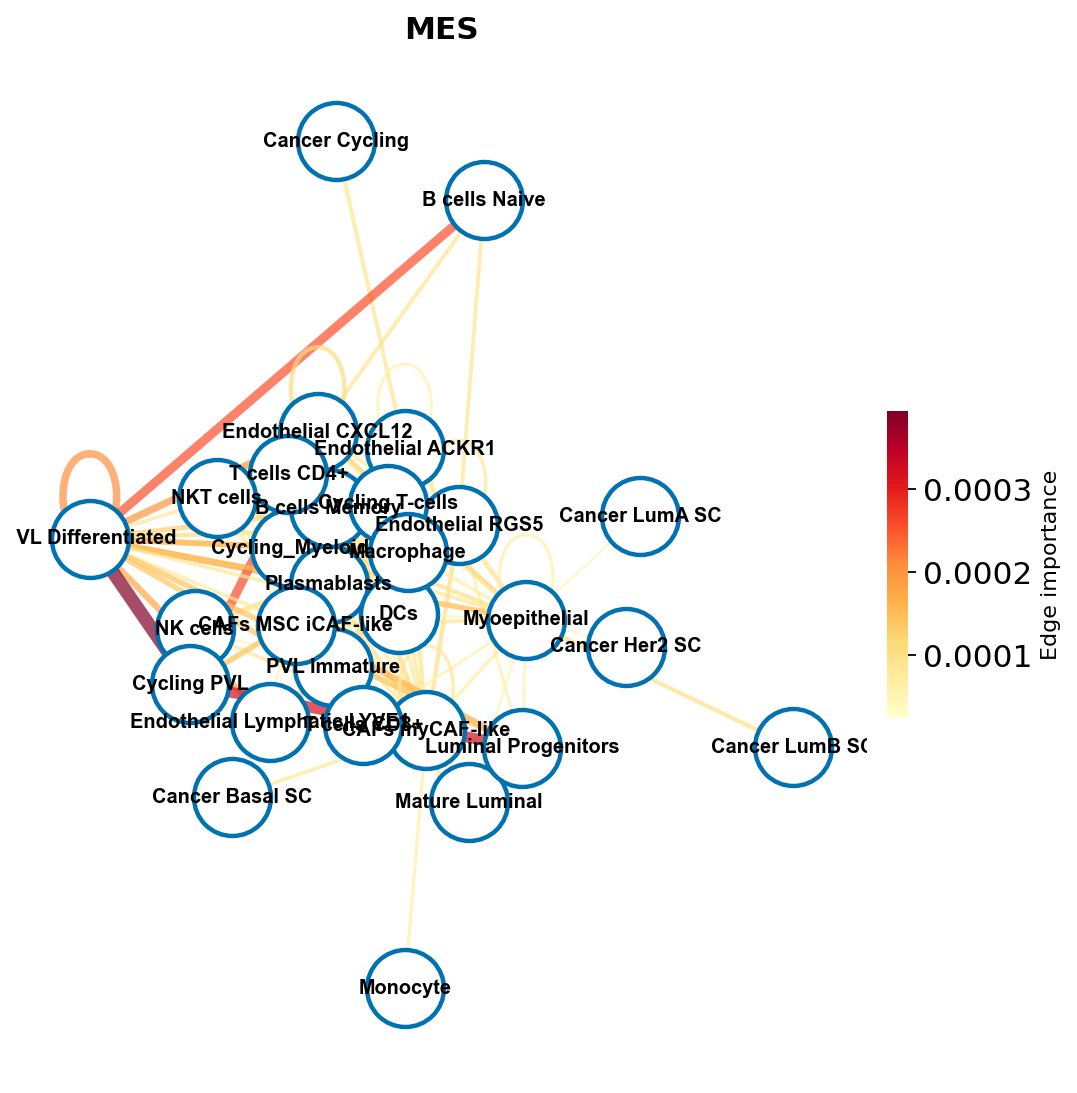

In [11]:
spice.tl.explain_edges(adata, n_explanations=300)
spice.pl.edge_network(adata, state_map={0: "EPI", 1: "H-EPI", 2: "H-MES", 3: "MES"}, save="xenium_v1_hallmark_edge_network.pdf")